In [9]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt 


In [10]:
tracks = pd.read_csv("../data/processed/tracks_cleaned_A2.csv", sep=';')
tracks.head()

,explicit,swear_EN,id_artist,year,day,n_tokens,album_id,popularity,bpm,album_name,...,spectral_complexity,month,flux,album_release_date,disc_number,n_sentences,swear_EN_words,pitch,symp_id,char_per_tok
0,True,6,ART04205421,2021,2,911,ALB00101,46.0,135.32,FOREVER AND EVER,...,25.7148,4,1.4499,2021-04-09,1.0,102,"['bitch', 'fuck', 'porno', 'pussy']",2311.1779,SYM0010101,4.1705
1,True,12,ART04205421,2020,6,675,ALB00101,46.0,129.37,FOREVER AND EVER,...,29.1089,3,1.3533,2021-04-09,1.0,56,"['escort', 'negro', 'sex', 'sexy', 'shit']",1892.1924,SYM0010102,4.2809
2,True,12,ART04205421,2021,19,758,ALB00101,39.0,133.68,FOREVER AND EVER,...,26.9762,2,1.3822,2021-04-09,1.0,88,"['bastardo', 'bitch', 'bitches', 'cock', 'fuck']",2484.3503,SYM0010103,4.0753
3,True,3,ART04205421,2019,8,382,ALB00102,47.0,162.22,OKAY OKAY 2,...,14.2956,3,1.5499,2025-05-16,1.0,37,"['fuck', 'porno', 'shit']",2984.6109,SYM0010201,4.0239
4,True,0,ART04205421,2020,29,429,ALB00103,41.0,105.87,FOREVER,...,36.6951,5,1.0886,2020-05-28,1.0,48,[],1572.0499,SYM0010301,3.9229


In [11]:
df_cluster = tracks[["bpm","rolloff","flux","flatness","spectral_complexity","pitch","loudness"]].dropna()
X = df_cluster.values

In [12]:
scaler = StandardScaler()
scaler.fit_transform(X)
scaler2 = MinMaxScaler()
X_minmax = scaler2.fit_transform(X)

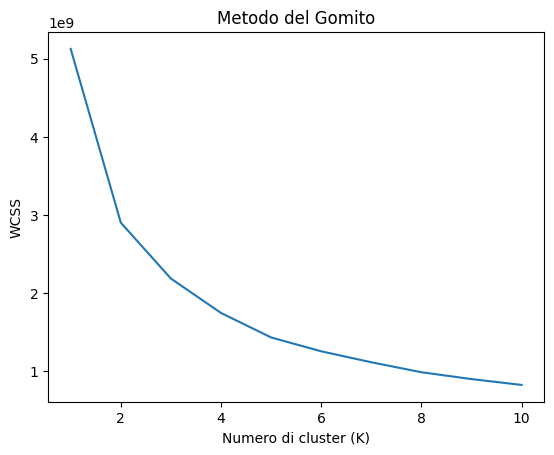

In [13]:
wcss = []

for i in range(1, 11): 
    kmeans = KMeans(n_clusters=i, init='random', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X)
  
    wcss.append(kmeans.inertia_)


plt.plot(range(1, 11), wcss)
plt.title('Metodo del Gomito')
plt.xlabel('Numero di cluster (K)')
plt.ylabel('WCSS')
plt.show()

In [14]:
silhouette_scores = []

for i in range(2, 11): 
    kmeans = KMeans(n_clusters=i, n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(X)
    # Calcola e registra il punteggio Silhouette
    silhouette_avg = silhouette_score(X, cluster_labels)
    silhouette_scores.append(silhouette_avg)
    print(f"K={i}, Silhouette Score: {silhouette_avg:.4f}")

K=2, Silhouette Score: 0.3951
K=3, Silhouette Score: 0.3190
K=4, Silhouette Score: 0.3204
K=5, Silhouette Score: 0.3236
K=6, Silhouette Score: 0.3180
K=7, Silhouette Score: 0.3121
K=8, Silhouette Score: 0.3164
K=9, Silhouette Score: 0.3140
K=10, Silhouette Score: 0.3135


In [15]:
# è stato scelto 5 come numero di clusters 
k_means = KMeans(5,n_init= 10, max_iter= 100, random_state= 94)

k_means.fit(X)

df_cluster["etichette"] = k_means.labels_




In [16]:
# facciamo l'analisi dei centroidi 
centroidi = k_means.cluster_centers_

colonne_feature = df_cluster.columns[:-1]

df_centroids = pd.DataFrame(centroidi, columns= colonne_feature)

df_centroids

,bpm,rolloff,flux,flatness,spectral_complexity,pitch,loudness
0,113.166212,1935.440581,1.236836,0.842295,31.565544,1936.691570,23.481200
1,116.430628,1271.500427,1.186591,0.884683,26.131643,2049.368519,23.278662
2,111.943717,1766.924312,1.338777,0.848254,26.917884,2527.147522,24.708822
3,112.875931,2762.871691,1.295237,0.786781,32.012884,2125.537853,22.391788
4,115.398915,1031.251035,1.276275,0.894222,23.282342,2652.254834,27.204082


In [17]:
tracks["audio_label"] = k_means.labels_


In [18]:

audio_map = {
    0: "Standard Urban",        # Valori medi
    1: "Elettrico & Aggressivo", # Rolloff alto
    2: "Lo-Fi / Chill",         # Rolloff basso
    3: "Mainstream Melodico",   # Pitch alto
    4: " Banger"  # Loudness alta
}

# 2. Crea una NUOVA colonna con le etichette
# Assumendo che la colonna numerica si chiami 'audio_cluster_id'
tracks['audio_label'] = tracks['audio_label'].map(audio_map)

tracks.head(10)



,explicit,swear_EN,id_artist,year,day,n_tokens,album_id,popularity,bpm,album_name,...,month,flux,album_release_date,disc_number,n_sentences,swear_EN_words,pitch,symp_id,char_per_tok,audio_label
0,True,6,ART04205421,2021,2,911,ALB00101,46.0,135.32,FOREVER AND EVER,...,4,1.4499,2021-04-09,1.0,102,"['bitch', 'fuck', 'porno', 'pussy']",2311.1779,SYM0010101,4.1705,Mainstream Melodico
1,True,12,ART04205421,2020,6,675,ALB00101,46.0,129.37,FOREVER AND EVER,...,3,1.3533,2021-04-09,1.0,56,"['escort', 'negro', 'sex', 'sexy', 'shit']",1892.1924,SYM0010102,4.2809,Mainstream Melodico
2,True,12,ART04205421,2021,19,758,ALB00101,39.0,133.68,FOREVER AND EVER,...,2,1.3822,2021-04-09,1.0,88,"['bastardo', 'bitch', 'bitches', 'cock', 'fuck']",2484.3503,SYM0010103,4.0753,Lo-Fi / Chill
3,True,3,ART04205421,2019,8,382,ALB00102,47.0,162.22,OKAY OKAY 2,...,3,1.5499,2025-05-16,1.0,37,"['fuck', 'porno', 'shit']",2984.6109,SYM0010201,4.0239,Banger
4,True,0,ART04205421,2020,29,429,ALB00103,41.0,105.87,FOREVER,...,5,1.0886,2020-05-28,1.0,48,[],1572.0499,SYM0010301,3.9229,Standard Urban
5,True,0,ART04205421,2020,21,387,ALB00103,29.0,92.02,FOREVER,...,5,1.0737,2020-05-28,1.0,62,[],1943.1810,SYM0010302,4.1606,Elettrico & Aggressivo
6,True,2,ART04205421,2020,17,680,ALB00103,23.0,129.82,FOREVER,...,4,1.2172,2020-05-28,1.0,82,"['bitches', 'sex']",2111.8930,SYM0010303,3.8177,Standard Urban
7,True,13,ART04205421,2020,29,657,ALB00103,24.0,129.95,FOREVER,...,5,1.3638,2020-05-28,1.0,82,"['ass', 'bitch', 'bitches', 'slut']",2137.0455,SYM0010304,4.0314,Mainstream Melodico
8,True,2,ART04205421,2023,8,584,ALB00104,50.0,124.14,MADE IN ITALY,...,2,1.2137,2023-02-09,1.0,82,"['sex', 'sexy']",1861.3738,SYM0010401,3.9358,Mainstream Melodico
9,True,5,ART04205421,2020,29,589,ALB00103,27.0,154.92,FOREVER,...,5,1.0910,2020-05-28,1.0,50,['bitches'],1757.9368,SYM0010305,3.8515,Standard Urban


In [19]:
tracks.to_csv("../data/processed/tracks_clean.csv", index= False)
